# Comparing Climate Indicator Engines: icclim vs xclim

**earthkit-climate** wraps two leading scientific climate index calculation engines under a unified Earthkit API:

1. **xclim**: A comprehensive, CF-compliant climate indicator library developed by Ouranos, featuring more than 80 indices and optimized resampling with flox.
2. **icclim**: An ECA&D/C3S-compliant index library developed by CERFACS, focused on the standard 49 ECA&D indices with native 5-day running window percentile bootstrapping.

This guide explores:
- **Fixed-threshold indicators**: Verifying mathematical equivalence between homologous indices (such as `fd` vs `frost_days` and `cdd` vs `maximum_consecutive_dry_days`).
- **Percentile-based indicators & backends**: Using `tx90p` and `tn10p` with `backend="auto"`, `backend="icclim"`, or `backend="xclim"`.
- **Methodological differences**: Comparing precomputed percentile arrays (xclim) against on-the-fly running-window bootstrapping (icclim).
- **Scalability with Dask**: Preserving lazy execution and chunking.
- **Engine Selection Guide**: A quick-reference matrix to help choose the best engine for your workflow.

## 1. Environment Setup and Sample Climate Data

We generate a synthetic 10-year daily meteorological dataset (1990-1999) with realistic seasonal variations for maximum temperature (`tasmax`), minimum temperature (`tasmin`), and daily precipitation (`pr`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from earthkit.climate import indicators
import xclim.core.calendar as xcal

# Create 10 years of synthetic daily meteorological data (1990-1999)
dates = pd.date_range("1990-01-01", "1999-12-31", freq="D")
np.random.seed(42)

doy = dates.dayofyear
seasonal_cycle = 14.0 + 12.0 * np.sin(2 * np.pi * (doy - 80) / 365.25)
noise_tx = np.random.normal(0, 3.0, len(dates))
noise_tn = np.random.normal(0, 2.5, len(dates))

tasmax = xr.DataArray(
    seasonal_cycle + 5.0 + noise_tx,
    coords={"time": dates},
    dims=["time"],
    name="tasmax",
    attrs={"units": "degC", "standard_name": "air_temperature"},
)
tasmin = xr.DataArray(
    seasonal_cycle - 5.0 + noise_tn,
    coords={"time": dates},
    dims=["time"],
    name="tasmin",
    attrs={"units": "degC", "standard_name": "air_temperature"},
)

# Precipitation with intermittent dry spells and wet events
is_wet = np.random.random(len(dates)) < 0.28
pr_vals = np.where(is_wet, np.random.exponential(7.5, len(dates)), 0.0)
pr = xr.DataArray(
    pr_vals,
    coords={"time": dates},
    dims=["time"],
    name="pr",
    attrs={"units": "mm/day", "standard_name": "precipitation_flux"},
)

ds = xr.Dataset({"tasmax": tasmax, "tasmin": tasmin, "pr": pr})
print(f"Dataset generated with {len(dates)} daily steps from {dates[0].date()} to {dates[-1].date()}.")
ds

Dataset generated with 3652 daily steps from 1990-01-01 to 1999-12-31.


<xarray.Dataset> Size: 117kB
Dimensions:  (time: 3652)
Coordinates:
  * time     (time) datetime64[ns] 29kB 1990-01-01 1990-01-02 ... 1999-12-31
Data variables:
    tasmax   (time) float64 29kB 8.758 6.899 9.305 11.98 ... 5.852 8.403 8.869
    tasmin   (time) float64 29kB -1.62 -4.751 -2.265 ... -4.142 -3.962 -1.936
    pr       (time) float64 29kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0

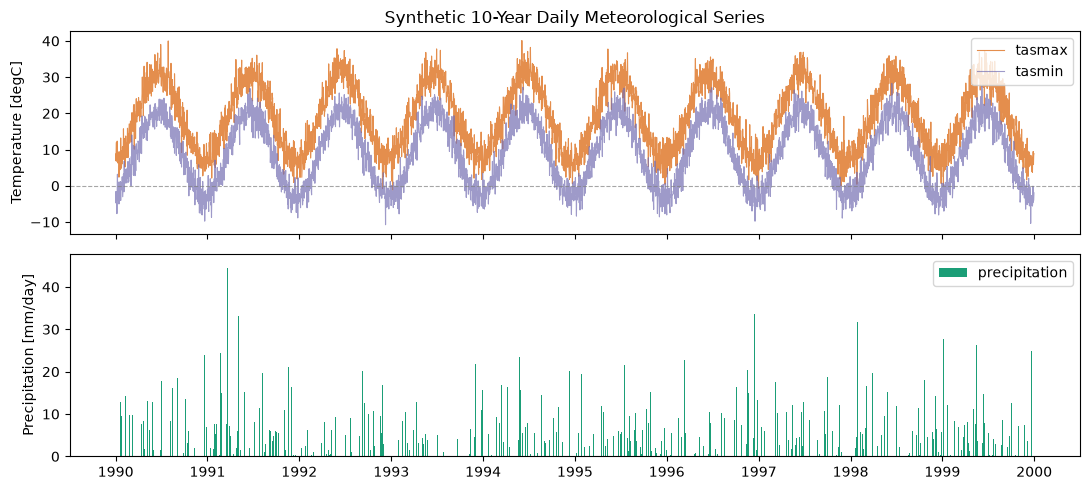

In [2]:
# Quick overview of the sample time series
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)

ax1.plot(ds["time"], ds["tasmax"], label="tasmax", color="#d95f02", alpha=0.7, lw=0.8)
ax1.plot(ds["time"], ds["tasmin"], label="tasmin", color="#7570b3", alpha=0.7, lw=0.8)
ax1.axhline(0, color="gray", ls="--", lw=0.8, alpha=0.7)
ax1.set_ylabel("Temperature [degC]")
ax1.legend(loc="upper right")
ax1.set_title("Synthetic 10-Year Daily Meteorological Series")

ax2.bar(ds["time"], ds["pr"], width=1.0, color="#1b9e77", label="precipitation")
ax2.set_ylabel("Precipitation [mm/day]")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 2. Fixed-Threshold Indicators: Numerical Equivalence and Boundary Nuances

When an indicator relies on daily fixed physical thresholds without multi-day spell tracking across periods (such as frost days with $TN < 0^\circ\text{C}$ or summer days with $TX > 25^\circ\text{C}$), `icclim` and `xclim` produce **100% identical numerical results**.

For multi-day spell indicators like **Consecutive Dry Days (CDD)**, they agree across virtually all years, with subtle differences occurring only when a prolonged dry spell crosses the December 31 / January 1 year boundary:
- **xclim**: Truncates run length calculations at the annual resample boundary.
- **icclim**: Follows ECA&D criteria allowing spell lengths to continue across year boundaries and attributing them according to ECA&D rules.

In [3]:
# 1. Frost Days (TN < 0 degC)
fd_icclim = indicators.fd(ds["tasmin"], freq="YS")
fd_xclim = indicators.frost_days(ds["tasmin"], freq="YS")

# Verify strict numerical equality
np.testing.assert_allclose(fd_icclim.values, fd_xclim.values)
print("Frost days (FD) are 100% identical across all 10 years.")

# 2. Maximum Consecutive Dry Days (RR < 1 mm/day)
cdd_icclim = indicators.cdd(ds["pr"], freq="YS")
cdd_xclim = indicators.maximum_consecutive_dry_days(ds["pr"], freq="YS")

# Display comparative table
df_comp = pd.DataFrame({
    "Year": [t.year for t in pd.to_datetime(fd_icclim.time.values)],
    "icclim FD": fd_icclim.values.astype(int),
    "xclim Frost Days": fd_xclim.values.astype(int),
    "icclim CDD": cdd_icclim.values.astype(int),
    "xclim Max Cons Dry Days": cdd_xclim.values.astype(int),
})

# Highlight boundary year difference
df_comp["CDD Match"] = df_comp["icclim CDD"] == df_comp["xclim Max Cons Dry Days"]
print("Annual Comparison:")
df_comp

/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/.venv/lib/python3.11/site-packages/xclim/core/cfchecks.py:77: UserWarning: Variable does not have a `cell_methods` attribute.
  _check_cell_methods(getattr(vardata, "cell_methods", None), data["cell_methods"])


Frost days (FD) are 100% identical across all 10 years.


/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/.venv/lib/python3.11/site-packages/xclim/core/cfchecks.py:77: UserWarning: Variable does not have a `cell_methods` attribute.
  _check_cell_methods(getattr(vardata, "cell_methods", None), data["cell_methods"])


Annual Comparison:


,Year,icclim FD,xclim Frost Days,icclim CDD,xclim Max Cons Dry Days,CDD Match
0,1990,73,73,16,16,True
1,1991,74,74,19,19,True
2,1992,82,82,13,13,True
3,1993,83,83,23,23,True
4,1994,83,83,21,12,False
5,1995,74,74,14,14,True
6,1996,85,85,20,20,True
7,1997,77,77,21,21,True
8,1998,82,82,14,14,True
9,1999,75,75,14,14,True


## 3. Percentile-based Indicators and the `backend` Parameter

Indicators like **TX90p** (warm day-times: percentage or count of days where $TX > 90\text{th percentile}$) involve a reference baseline period.

Here lies a major methodological distinction between engines:
- **xclim**: Employs a decoupled architecture where the day-of-the-year percentile array (`tasmax_per`) is computed separately (e.g. via `xclim.core.calendar.percentile_doy`). This is ideal when working with external percentiles from reanalysis or multi-model ensembles.
- **icclim**: Incorporates the full ECA&D bootstrap method within a 5-day window over a baseline period (`base_period_time_range`), preventing artificial discontinuities between in-base and out-of-base years.

In **earthkit-climate**, the unified indicator `tx90p` provides a `backend` parameter:
- `backend="icclim"`: Uses automatic running-window and bootstrapping over `base_period_time_range`.
- `backend="xclim"`: Uses the supplied precalculated percentile `tasmax_per`.
- `backend="auto"`: Intelligently dispatches to `xclim` if `tasmax_per` is provided, or `icclim` if `base_period_time_range` is supplied.

In [4]:
# Mode 1: backend="icclim" with in-base reference period 1990-1995
base_range = ["1990-01-01", "1995-12-31"]

tx90p_icclim = indicators.tx90p(
    ds["tasmax"],
    base_period_time_range=base_range,
    freq="YS",
    backend="icclim",
)

# Mode 2: backend="xclim" with Day-of-Year percentile computed over 1990-1995
base_slice = ds["tasmax"].sel(time=slice(base_range[0], base_range[1]))
per_90_doy = xcal.percentile_doy(base_slice, per=90, window=5)

tx90p_xclim = indicators.tx90p(
    ds["tasmax"],
    tasmax_per=per_90_doy,
    freq="YS",
    backend="xclim",
)

# Mode 3: backend="auto" (auto-selects icclim because no tasmax_per is passed)
tx90p_auto = indicators.tx90p(
    ds["tasmax"],
    base_period_time_range=base_range,
    freq="YS",
    backend="auto",
)
assert tx90p_auto.equals(tx90p_icclim)
print("Auto-dispatch confirmed: tx90p with base_period_time_range dispatches to icclim.")

Auto-dispatch confirmed: tx90p with base_period_time_range dispatches to icclim.


/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/.venv/lib/python3.11/site-packages/xclim/core/cfchecks.py:77: UserWarning: Variable does not have a `cell_methods` attribute.
  _check_cell_methods(getattr(vardata, "cell_methods", None), data["cell_methods"])


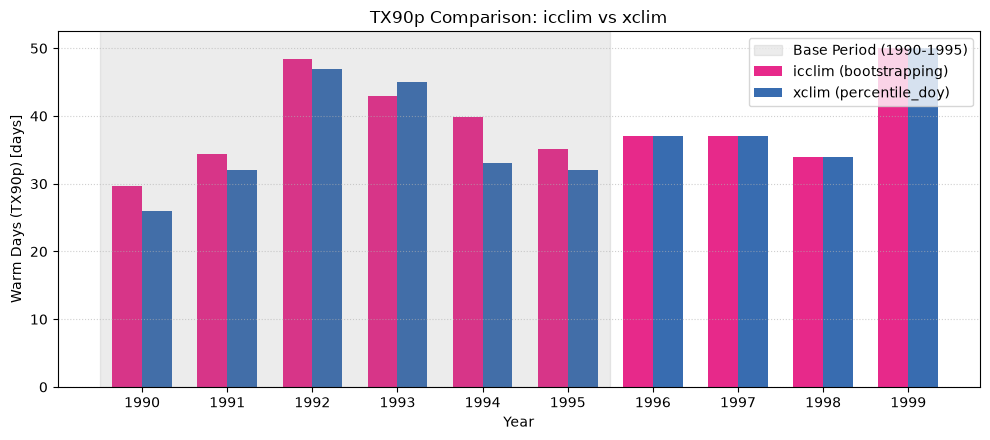

Correlation between icclim and xclim outputs: 0.9491
Mean absolute difference: 1.94 days


In [5]:
# Visual comparison between icclim and xclim percentiles
years = [t.year for t in pd.to_datetime(tx90p_icclim.time.values)]

plt.figure(figsize=(10, 4.5))
bar_width = 0.35
x_idx = np.arange(len(years))

plt.bar(x_idx - bar_width / 2, tx90p_icclim.values, width=bar_width, label="icclim (bootstrapping)", color="#e7298a")
plt.bar(x_idx + bar_width / 2, tx90p_xclim.values.squeeze(), width=bar_width, label="xclim (percentile_doy)", color="#386cb0")

plt.axvspan(-0.5, 5.5, color="gray", alpha=0.15, label="Base Period (1990-1995)")
plt.xticks(x_idx, years)
plt.xlabel("Year")
plt.ylabel("Warm Days (TX90p) [days]")
plt.title("TX90p Comparison: icclim vs xclim")
plt.legend(loc="upper right")
plt.grid(axis="y", ls=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Quantify closeness
corr = np.corrcoef(tx90p_icclim.values, tx90p_xclim.values.squeeze())[0, 1]
print(f"Correlation between icclim and xclim outputs: {corr:.4f}")
print("Mean absolute difference:", np.mean(np.abs(tx90p_icclim.values - tx90p_xclim.values.squeeze())), "days")

## 4. Multi-variable Temperature Range Indicators

Both engines provide multi-variable indices operating across simultaneous variables:
- **Diurnal Temperature Range (`dtr` in icclim vs `daily_temperature_range` in xclim)**: Mean daily difference between maximum and minimum temperature ($TX - TN$).
- **Extreme Temperature Range (`etr` in icclim vs `extreme_temperature_range` in xclim)**: Intra-period difference between the period's highest maximum and lowest minimum temperature ($TX_x - TN_n$).

In [6]:
# 1. Diurnal Temperature Range (DTR)
dtr_icclim = indicators.dtr(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")
dtr_xclim = indicators.daily_temperature_range(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")

np.testing.assert_allclose(dtr_icclim.values, dtr_xclim.values)
print("DTR is numerically identical between icclim and xclim.")

# 2. Extreme Temperature Range (ETR)
etr_icclim = indicators.etr(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")
etr_xclim = indicators.extreme_temperature_range(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")

np.testing.assert_allclose(etr_icclim.values, etr_xclim.values)
print("ETR is numerically identical between icclim and xclim.")

# Comparative summary table
df_ranges = pd.DataFrame({
    "Year": [t.year for t in pd.to_datetime(dtr_icclim.time.values)],
    "icclim DTR [degC]": np.round(dtr_icclim.values, 2),
    "xclim DTR [degC]": np.round(dtr_xclim.values, 2),
    "icclim ETR [degC]": np.round(etr_icclim.values, 2),
    "xclim ETR [degC]": np.round(etr_xclim.values, 2),
})
df_ranges

DTR is numerically identical between icclim and xclim.


/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/.venv/lib/python3.11/site-packages/xclim/core/cfchecks.py:77: UserWarning: Variable does not have a `cell_methods` attribute.
  _check_cell_methods(getattr(vardata, "cell_methods", None), data["cell_methods"])


ETR is numerically identical between icclim and xclim.


/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/.venv/lib/python3.11/site-packages/xclim/core/cfchecks.py:77: UserWarning: Variable does not have a `cell_methods` attribute.
  _check_cell_methods(getattr(vardata, "cell_methods", None), data["cell_methods"])


,Year,icclim DTR [degC],xclim DTR [degC],icclim ETR [degC],xclim ETR [degC]
0,1990,10.19,10.19,49.76,49.76
1,1991,10.10,10.10,44.94,44.94
2,1992,10.40,10.40,48.61,48.61
3,1993,10.26,10.26,45.55,45.55
4,1994,10.27,10.27,48.02,48.02
5,1995,10.08,10.08,46.35,46.35
6,1996,10.12,10.12,45.35,45.35
7,1997,10.16,10.16,45.80,45.80
8,1998,10.11,10.11,43.99,43.99
9,1999,10.02,10.02,47.53,47.53


## 5. Parallel Execution and Dask Chunking

Both `icclim` and `xclim` integrated in `earthkit-climate` preserve Dask chunking and lazy execution, enabling processing of large distributed datasets without loading entire cubes into memory.

In [7]:
# Chunk the dataset along the time dimension
ds_dask = ds.chunk({"time": 365})
print("Chunked DataArray:", ds_dask["tasmax"].data)

# Compute summer days lazily
res_lazy_su = indicators.su(ds_dask["tasmax"], freq="YS")
print("Has Dask computational graph:", hasattr(res_lazy_su.data, "dask"))

# Compute values on demand
computed_su = res_lazy_su.compute()
print("Computed values across years:", computed_su.values)

Chunked DataArray: dask.array<xarray-tasmax, shape=(3652,), dtype=float64, chunksize=(365,), chunktype=numpy.ndarray>
Has Dask computational graph: True
Computed values across years: [118. 116. 122. 112. 119. 122. 123. 119. 110. 125.]


## 6. Engine Selection Guide

| Criterion | Choose `icclim` | Choose `xclim` |
| :--- | :--- | :--- |
| **Catalog Scope** | Standard 49 ECA&D and C3S climate indices. | Broad catalog (>80 indices) including SPEI, fire weather, degree-days. |
| **Percentile Baseline** | Automatic in-base bootstrapping with 5-day running window (`base_period_time_range`). | Flexible precomputed percentiles (`tasmax_per`) from external climatologies. |
| **Data Resampling** | Direct Pandas/Xarray resampling. | Fast resampling powered by `flox`. |
| **Output Naming** | Official ECA&D short names (e.g. `SU`, `FD`, `TX90p`, `CDD`). | CF-standard names and descriptive identifiers (`summer_days`, `frost_days`). |
| **earthkit-climate Mode** | Explicit `backend="icclim"` or via short aliases (`fd`, `su`, `cdd`). | Explicit `backend="xclim"` or via descriptive names (`frost_days`). |